# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Dimas Eka Maulana
- **Email:** dimas.eka.maulana.tik24@stu.pnj.ac.id
- **ID Dicoding:** ds128b6y0458

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari libur selama periode 2011–2012, dan pada jam berapa puncak permintaannya, agar operator dapat menyesuaikan distribusi sepeda pada jam sibuk?
- **Pertanyaan 2:** Seberapa besar (dalam persen) penurunan rata-rata penyewaan harian pada cuaca berkabut/berawan dan hujan/salju dibandingkan cuaca cerah selama 2011–2012, dan pada musim apa penurunannya paling besar, agar operator dapat menyiapkan strategi operasional saat cuaca buruk?

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load day_df dan hour_df.

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

display(day_df.head())
display(hour_df.head())
print("Ukuran day_df :", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Ukuran day_df : (731, 16)
Ukuran hour_df: (17379, 17)


**Insight:**
- day_df berisi 731 hari (1 Jan 2011 – 31 Des 2012) dengan 16 kolom, hour_df berisi 17.379 baris per jam dengan 17 kolom (tambahan kolom `hr`).
- Kolom kategori (season, yr, weathersit, weekday) masih berupa kode angka, dan suhu/kelembapan/kecepatan angin masih ternormalisasi.

### Assessing Data

#### Identifying data quality problem

In [3]:
day_df.info()
hour_df.info()
print("Missing value :", day_df.isna().sum().sum(), "|", hour_df.isna().sum().sum())
print("Duplikat      :", day_df.duplicated().sum(), "|", hour_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Colum

In [4]:
# Invalid value: kelembapan 0%
print(day_df[day_df["hum"] == 0][["dteday", "hum", "cnt"]])
print("Baris hum = 0 di hour_df:", (hour_df["hum"] == 0).sum())

# Jam yang tidak tercatat di hour_df (seharusnya 731 x 24 baris)
print("Jam hilang di hour_df:", 731 * 24 - len(hour_df))

# Kategori cuaca 4 (jumlahnya sangat sedikit)
print(hour_df["weathersit"].value_counts().sort_index())

        dteday  hum  cnt
68  2011-03-10  0.0  623
Baris hum = 0 di hour_df: 22
Jam hilang di hour_df: 165
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


In [5]:
# Outlier dengan metode IQR
def jumlah_outlier(df, kolom):
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((df[kolom] < q1 - 1.5 * iqr) | (df[kolom] > q3 + 1.5 * iqr)).sum()

for k in ["windspeed", "casual", "cnt"]:
    print(f"Outlier {k}: {jumlah_outlier(day_df, k)}")

display(day_df.nsmallest(3, "cnt")[["dteday", "cnt", "weathersit"]])

Outlier windspeed: 13
Outlier casual: 44
Outlier cnt: 0


,dteday,cnt,weathersit
667,2012-10-29,22,3
26,2011-01-27,431,1
725,2012-12-26,441,3


**Steps to Take:**
- Mengubah tipe data `dteday` dari string menjadi datetime (inaccurate value).
- Mengubah kode kategori (season, yr, weekday, workingday, weathersit) menjadi label yang mudah dibaca dan mengembalikan temp, atemp, hum, windspeed ke satuan asli (inconsistent value).
- Mengganti `hum = 0` (invalid value) dengan nilai interpolasi dari hari/jam di sekitarnya.
- Menggabungkan cuaca kategori 4 ke "Hujan/Salju" karena hanya 3 baris.
- Outlier tidak dihapus karena merupakan kejadian nyata (misalnya penyewaan sangat rendah saat badai).

**Insight:**
- Tidak ada missing value dan duplikat pada kedua dataset.
- Ada 1 hari dengan kelembapan 0% (2011-03-10) dan 22 jam di hour_df, tidak masuk akal secara fisik.
- hour_df kehilangan 165 jam (jam tanpa transaksi tidak tercatat), sehingga rata-rata per jam sedikit lebih tinggi dari kondisi sebenarnya.
- Outlier: windspeed 13 hari, casual 44 hari, cnt 0 hari. Hari dengan penyewaan terendah adalah 2012-10-29 (22 sepeda), bertepatan dengan Badai Sandy.

### Cleaning Data

#### Fixing data type, inconsistent, and invalid value.

In [6]:
def bersihkan(df):
    df = df.copy()
    df["dteday"] = pd.to_datetime(df["dteday"])
    df["season"] = df["season"].map({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})
    df["yr"] = df["yr"].map({0: 2011, 1: 2012})
    df["weekday"] = df["weekday"].map({0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu",
                                       4: "Kamis", 5: "Jumat", 6: "Sabtu"})
    df["hari"] = df["workingday"].map({1: "Hari Kerja", 0: "Hari Libur/Akhir Pekan"})
    df["cuaca"] = df["weathersit"].map({1: "Cerah", 2: "Berkabut/Berawan",
                                        3: "Hujan/Salju", 4: "Hujan/Salju"})
    df["temp"] = df["temp"] * 41
    df["atemp"] = df["atemp"] * 50
    df["hum"] = df["hum"] * 100
    df["windspeed"] = df["windspeed"] * 67
    df["hum"] = df["hum"].replace(0, np.nan).interpolate()
    return df

day_df = bersihkan(day_df)
hour_df = bersihkan(hour_df)

print("Missing value setelah cleaning:", day_df.isna().sum().sum(), "|", hour_df.isna().sum().sum())
print("Hum minimum:", round(day_df["hum"].min(), 1), "|", round(hour_df["hum"].min(), 1))
day_df.head()

Missing value setelah cleaning: 0 | 0
Hum minimum: 18.8 | 8.0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,hari,cuaca
0,1,2011-01-01,Spring,2011,1,0,Sabtu,0,2,14.110847,18.18125,80.5833,10.749882,331,654,985,Hari Libur/Akhir Pekan,Berkabut/Berawan
1,2,2011-01-02,Spring,2011,1,0,Minggu,0,2,14.902598,17.68695,69.6087,16.652113,131,670,801,Hari Libur/Akhir Pekan,Berkabut/Berawan
2,3,2011-01-03,Spring,2011,1,0,Senin,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349,Hari Kerja,Cerah
3,4,2011-01-04,Spring,2011,1,0,Selasa,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562,Hari Kerja,Cerah
4,5,2011-01-05,Spring,2011,1,0,Rabu,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600,Hari Kerja,Cerah


**Insight:**
- Semua masalah pada tahap Assessing sudah ditangani: tipe tanggal benar, kategori berlabel, satuan kembali ke asli, dan tidak ada lagi kelembapan 0%.
- Outlier sengaja dipertahankan karena mencerminkan kejadian nyata.

## Exploratory Data Analysis (EDA)

### Explore Pertanyaan 1: Hari Kerja vs Hari Libur

In [7]:
print(hour_df.groupby("hari")["cnt"].mean().round(1))

pola_jam = hour_df.groupby(["hari", "hr"])["cnt"].mean().unstack(0).round(0)
print("\nJam puncak:\n", pola_jam.idxmax())
print("\nNilai puncak:\n", pola_jam.max())

hari
Hari Kerja                193.2
Hari Libur/Akhir Pekan    181.4
Name: cnt, dtype: float64

Jam puncak:
 hari
Hari Kerja                17
Hari Libur/Akhir Pekan    13
dtype: int64

Nilai puncak:
 hari
Hari Kerja                525.0
Hari Libur/Akhir Pekan    373.0
dtype: float64


### Explore Pertanyaan 2: Dampak Cuaca terhadap Penyewaan Harian

In [8]:
cuaca_df = day_df.groupby("cuaca")["cnt"].agg(["mean", "count"]).round(0)
print(cuaca_df)

rata = day_df.groupby("cuaca")["cnt"].mean()
print("\nPenurunan vs Cerah (%):")
print(((1 - rata[["Berkabut/Berawan", "Hujan/Salju"]] / rata["Cerah"]) * 100).round(1))

urutan = ["Cerah", "Berkabut/Berawan", "Hujan/Salju"]
pv = day_df.pivot_table(index="season", columns="cuaca", values="cnt", aggfunc="mean")[urutan]
turun = ((1 - pv[["Berkabut/Berawan", "Hujan/Salju"]].div(pv["Cerah"], axis=0)) * 100).round(1)
print("\nPenurunan per musim (%):")
print(turun)

                    mean  count
cuaca                          
Berkabut/Berawan  4036.0    247
Cerah             4877.0    463
Hujan/Salju       1803.0     21

Penurunan vs Cerah (%):
cuaca
Berkabut/Berawan    17.2
Hujan/Salju         63.0
Name: cnt, dtype: float64

Penurunan per musim (%):
cuaca   Berkabut/Berawan  Hujan/Salju
season                               
Fall                11.2         53.2
Spring              16.1         66.7
Summer              23.6         78.9
Winter               7.7         61.1


**Insight:**
- Rata-rata per jam hari kerja (193) hanya sedikit lebih tinggi dari hari libur (181), tetapi polanya berbeda: hari kerja punya dua puncak (jam 08:00 dan 17:00, puncak tertinggi 525 sepeda pada jam 17:00), sedangkan hari libur punya satu puncak di siang hari (jam 13:00).
- Rata-rata penyewaan harian: cerah 4.877 (463 hari), berkabut/berawan 4.036 (247 hari), hujan/salju 1.803 (hanya 21 hari).
- Dibanding cuaca cerah, penurunan sebesar 17,2% (berkabut/berawan) dan 63,0% (hujan/salju).
- Penurunan terbesar terjadi pada musim Summer (23,6% berkabut, 78,9% hujan/salju), terkecil pada Winter untuk berkabut (7,7%) dan Fall untuk hujan/salju (53,2%).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

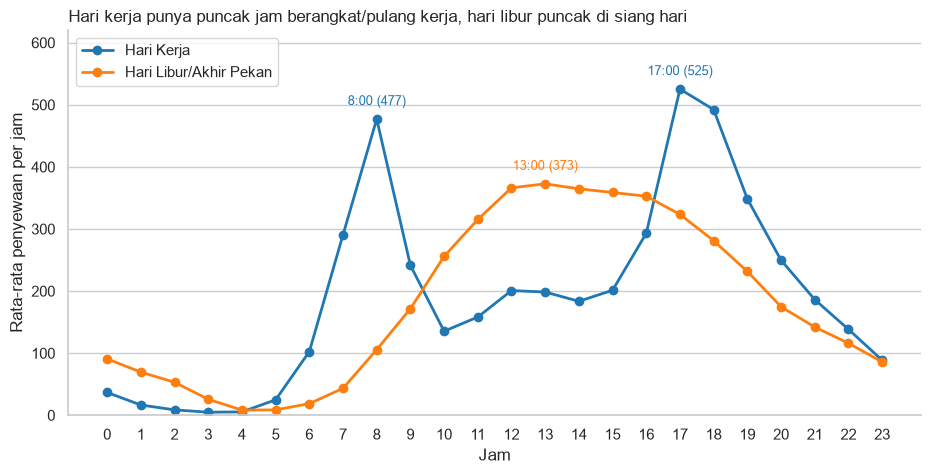

In [9]:
pola = hour_df.groupby(["hari", "hr"])["cnt"].mean().reset_index()
warna = {"Hari Kerja": "#1f77b4", "Hari Libur/Akhir Pekan": "#ff7f0e"}

fig, ax = plt.subplots(figsize=(11, 5))
for nama, g in pola.groupby("hari"):
    ax.plot(g["hr"], g["cnt"], marker="o", linewidth=2, label=nama, color=warna[nama])
    titik = [g.loc[g["cnt"].idxmax()]]
    if nama == "Hari Kerja":
        titik.append(g[g["hr"] == 8].iloc[0])
    for t in titik:
        ax.annotate(f"{int(t['hr'])}:00 ({t['cnt']:.0f})", (t["hr"], t["cnt"]),
                    textcoords="offset points", xytext=(0, 10), ha="center",
                    fontsize=9, color=warna[nama])

ax.set_ylim(0, 620)
ax.grid(axis="x", visible=False)
ax.set_title("Hari kerja punya puncak jam berangkat/pulang kerja, hari libur puncak di siang hari",
             loc="left", fontsize=12)
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_xticks(range(24))
ax.legend()
sns.despine()
plt.show()

### Pertanyaan 2:

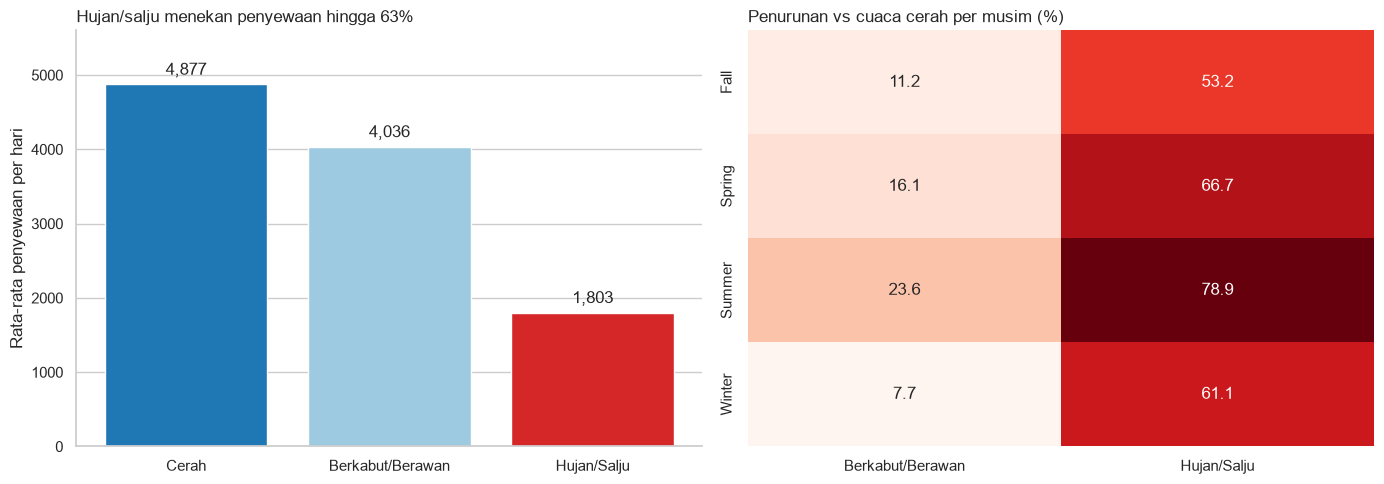

In [10]:
urutan = ["Cerah", "Berkabut/Berawan", "Hujan/Salju"]
palet = {"Cerah": "#1f77b4", "Berkabut/Berawan": "#9ecae1", "Hujan/Salju": "#d62728"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rata = day_df.groupby("cuaca")["cnt"].mean().reindex(urutan)
bars = axes[0].bar(rata.index, rata.values, color=[palet[c] for c in rata.index])
for b, v in zip(bars, rata.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 80, f"{v:,.0f}", ha="center", va="bottom")
axes[0].set_ylim(0, 5600)
axes[0].grid(axis="x", visible=False)
axes[0].set_title("Hujan/salju menekan penyewaan hingga 63%", loc="left", fontsize=12)
axes[0].set_ylabel("Rata-rata penyewaan per hari")
axes[0].set_xlabel("")
sns.despine(ax=axes[0])

sns.heatmap(turun, annot=True, fmt=".1f", cmap="Reds", cbar=False, ax=axes[1])
axes[1].set_title("Penurunan vs cuaca cerah per musim (%)", loc="left", fontsize=12)
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Insight:** 
- Pertanyaan 1: Operator perlu menyiapkan sepeda lebih banyak pada pukul 07:00–09:00 dan 16:00–19:00 di hari kerja, sedangkan di hari libur kebutuhan memuncak sekitar pukul 11:00–15:00.
- Pertanyaan 2: Cuaca hujan/salju memangkas penyewaan hingga 63%, jauh lebih besar daripada berkabut/berawan (17%). Dampak terbesar terjadi di musim Summer.
- Catatan: hari hujan/salju hanya 21 hari (3–10 hari per musim), sehingga persentase per musim bersifat indikatif.

## Analisis Lanjutan

**Tujuan:** Teknik **binning (manual grouping)** dipakai untuk mengelompokkan hari ke dalam kategori suhu (Dingin <10°C, Sejuk 10–20°C, Hangat 20–30°C, Panas >30°C) dan kategori permintaan (Rendah ≤3.000, Sedang 3.001–6.000, Tinggi >6.000 sepeda/hari). Tujuannya melihat pada rentang suhu mana Permintaan tinggi paling sering muncul saat suhu 20–30°C

                  count    mean
kategori_suhu                  
Dingin (<10°C)       60  1678.0
Sejuk (10-20°C)     299  3692.0
Hangat (20-30°C)    300  5662.0
Panas (>30°C)        72  5410.0
kategori_permintaan  Rendah  Sedang  Tinggi
kategori_suhu                              
Dingin (<10°C)         91.7     8.3     0.0
Sejuk (10-20°C)        35.5    56.5     8.0
Hangat (20-30°C)        3.7    53.3    43.0
Panas (>30°C)           0.0    62.5    37.5


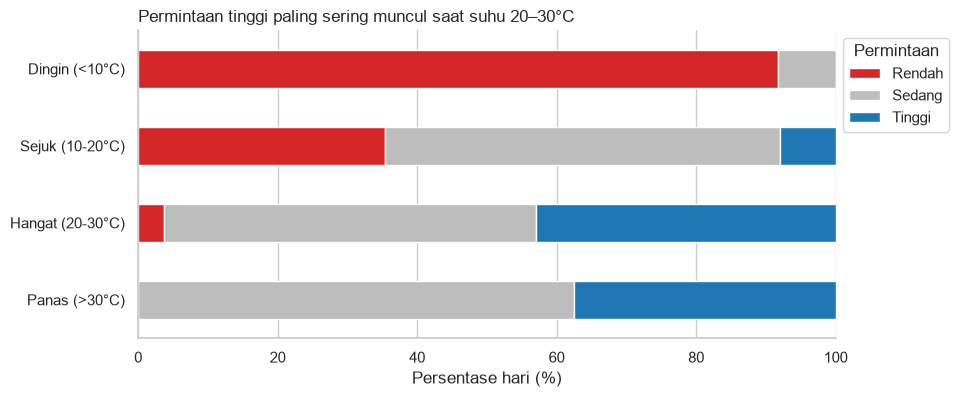

In [11]:
day_df["kategori_suhu"] = pd.cut(day_df["temp"], bins=[-np.inf, 10, 20, 30, np.inf],
    labels=["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"])
day_df["kategori_permintaan"] = pd.cut(day_df["cnt"], bins=[0, 3000, 6000, np.inf],
    labels=["Rendah", "Sedang", "Tinggi"])

print(day_df.groupby("kategori_suhu", observed=True)["cnt"].agg(["count", "mean"]).round(0))

ct = pd.crosstab(day_df["kategori_suhu"], day_df["kategori_permintaan"], normalize="index") * 100
print(ct.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
ct.iloc[::-1].plot(kind="barh", stacked=True, ax=ax, color=["#d62728", "#bdbdbd", "#1f77b4"])
ax.set_title("Permintaan tinggi paling sering muncul saat suhu 20–30°C", loc="left")
ax.set_xlabel("Persentase hari (%)")
ax.set_ylabel("")
ax.legend(title="Permintaan", bbox_to_anchor=(1, 1))
sns.despine()
plt.show()

# Simpan data bersih untuk dashboard
os.makedirs("dashboard", exist_ok=True)
day_df.to_csv("dashboard/main_data.csv", index=False)
hour_df.to_csv("dashboard/hour_data.csv", index=False)

**Insight:**
- Suhu Dingin (60 hari): rata-rata hanya 1.678 sepeda/hari, 92% harinya berpermintaan rendah.
- Suhu Hangat 20–30°C (300 hari): rata-rata tertinggi, 5.662 sepeda/hari, dan 43% harinya berpermintaan tinggi.
- Suhu Panas >30°C (72 hari) sedikit lebih rendah (5.410) dengan 37,5% hari berpermintaan tinggi. Artinya suhu ideal ada di kisaran 20–30°C.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata penyewaan per jam hari kerja (193) hanya sedikit di atas hari libur (181), namun pola jamnya berbeda. Hari kerja memuncak pada jam 08:00 dan 17:00 (tertinggi 525 sepeda), sedangkan hari libur memuncak sekitar jam 13:00.
- **Conclusion pertanyaan 2:** Dibanding cuaca cerah, penyewaan turun 17,2% saat berkabut/berawan dan 63,0% saat hujan/salju. Penurunan terbesar terjadi di musim Summer (23,6% dan 78,9%).

**Rekomendasi Action Item:**
- Pada hari kerja, tambah stok dan lakukan redistribusi sepeda sebelum pukul 07:00 dan 16:00 di titik-titik ramai. Lakukan perawatan armada di luar jam sibuk (sekitar 00:00–05:00 atau 10:00–15:00).
- Pada hari libur, alihkan stok ke area wisata/taman dengan puncak sekitar pukul 11:00–15:00.
- Manfaatkan prakiraan cuaca: saat diprediksi hujan, kurangi sepeda di lapangan dan jadwalkan perawatan. Saat cuaca cerah atau suhu 20–30°C, siapkan armada penuh.
- Kumpulkan data hari hujan lebih banyak agar analisis per musim lebih andal.